> **Versão pública (2026).** Notebook original, executado em 2021 no Windows (Python 3.7, Anaconda), com as bibliotecas na mesma pasta. As saídas são as originais. Para rodar de novo, veja o [README desta pasta](README.md).

In [1]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit
from sklearn.model_selection import StratifiedKFold, KFold

######################

import AleTransforms as trf
import AleDatasetAnalysis as dsa

import AleLearners as lrn
import AleMLAnalysis as aml

import AleExplainers as exp

In [2]:
import importlib

importlib.reload(trf)
importlib.reload(dsa)

importlib.reload(lrn)
importlib.reload(aml)

importlib.reload(exp)

<module 'AleExplainers' from '<PASTA_DAS_BIBLIOTECAS>\\AleExplainers.py'>

In [3]:
df = pd.read_csv('datasets/Churn_Modelling.csv')

In [4]:
df = df.drop('RowNumber', axis = 1)

In [5]:
df_nulls = pd.DataFrame(df.isnull().sum(), columns = ['QTD'])
df_nulls = df_nulls[df_nulls['QTD'] > 0]
df_nulls = df_nulls.sort_values('QTD', ascending = True)
display(df_nulls)

,QTD


In [6]:
list(df.columns)

['CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

# Análise Exploratória

In [7]:
analise_exp = dsa.DistribuicoesDataset(df, num_div = 20, num_cat = 10)

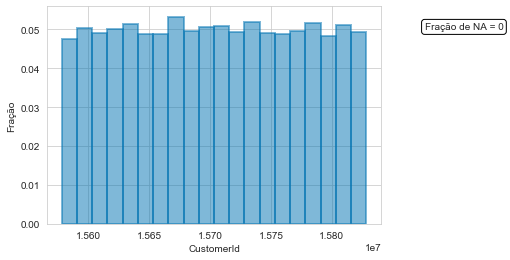

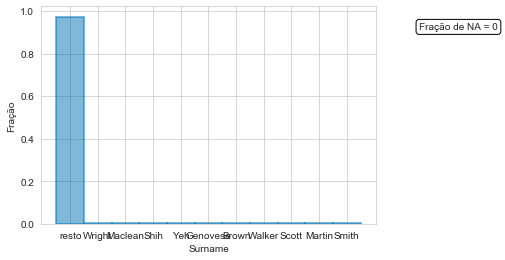

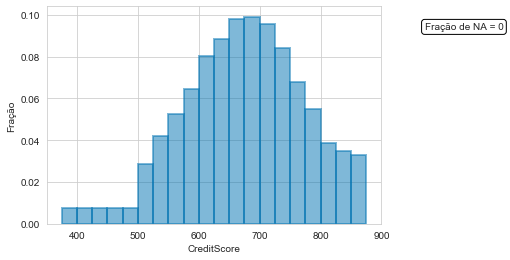

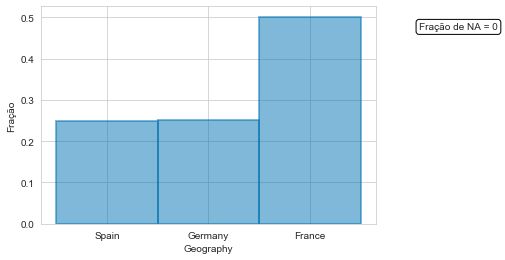

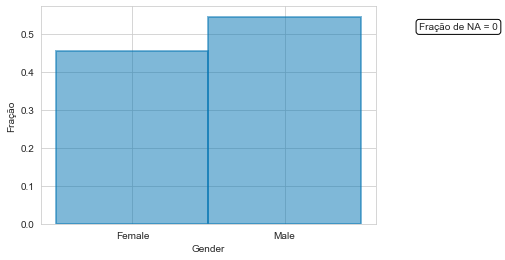

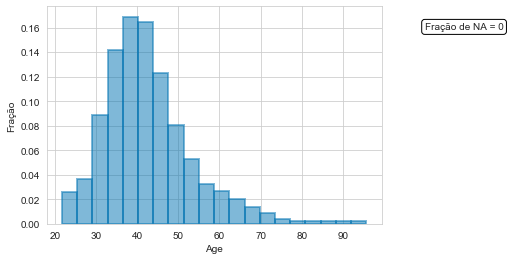

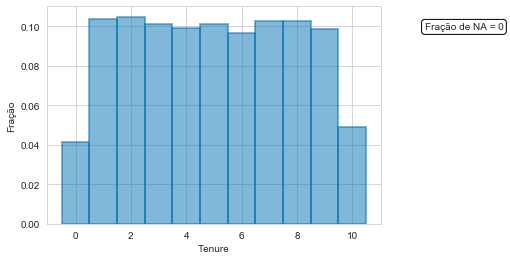

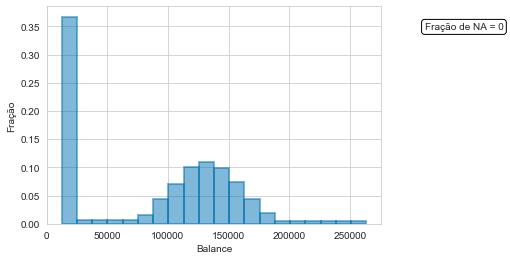

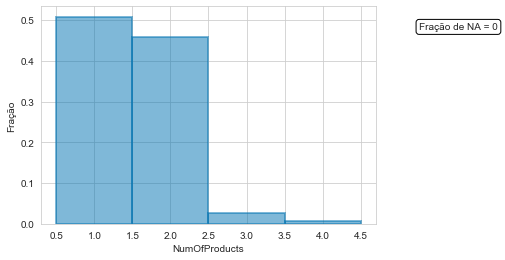

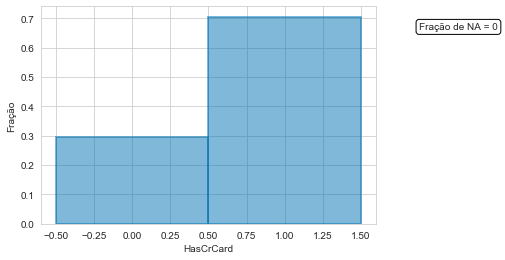

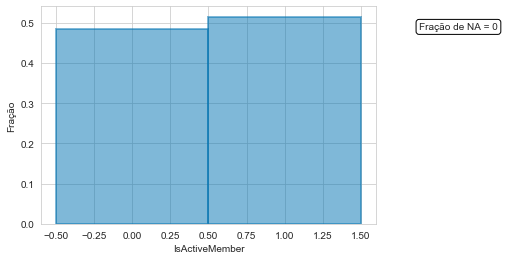

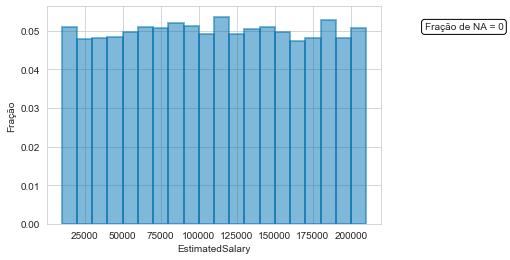

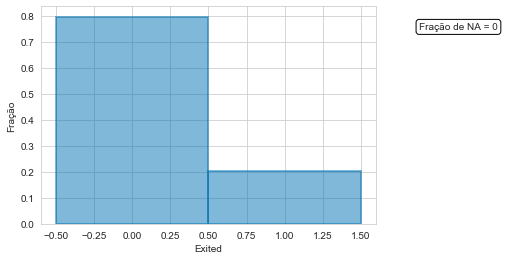

In [8]:
analise_exp.grafico_distribuicao()

QTD  Código                                          Categoria
0   9733       0  Peppin, Hardiman, Hardacre, Percy, Perkin, Per...
1     24       1                                             Wright
2     24       2                                            Maclean
3     25       3                                               Shih
4     25       4                                                Yeh
5     25       5                                           Genovese
6     26       6                                              Brown
7     28       7                                             Walker
8     29       8                                              Scott
9     29       9                                             Martin
10    32      10                                              Smith

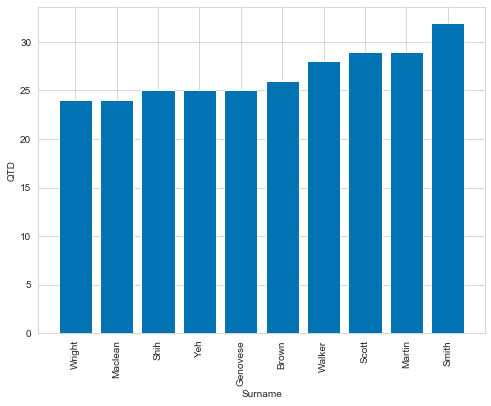

In [9]:
df_sur = analise_exp.info_distribuicao('Surname')
display(df_sur)

import seaborn as sns
import matplotlib.pyplot as plt

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [8, 6])
    ax.bar(df_sur.iloc[1:]['Categoria'], df_sur.iloc[1:]['QTD'], color = paleta_cores[0])
    ax.set_ylabel('QTD')
    ax.set_xlabel('Surname')
    ax.set_ylim(bottom = 0.0)
    plt.xticks(rotation = 90)
    plt.show()

In [10]:
colunas_id = ['CustomerId', 'Surname']
nome_alvo = 'Exited'

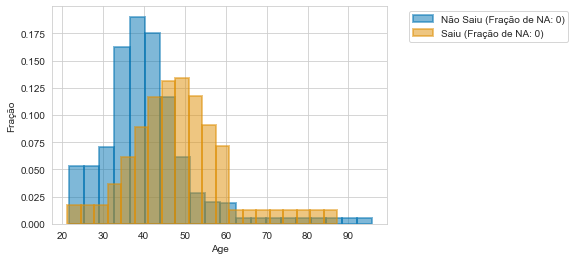

In [11]:
dict_dfs = {'Não Saiu': df[df[nome_alvo] == 0],
           'Saiu': df[df[nome_alvo] == 1]}
analise_exp2 = dsa.AvaliaDatasetsDistribuicoes(dict_dfs, num_div = 10, num_cat = 10)
analise_exp2.trata_coluna(dict_dfs, 'Age')
analise_exp2.grafico_distribuicao('Age', bins = 20)

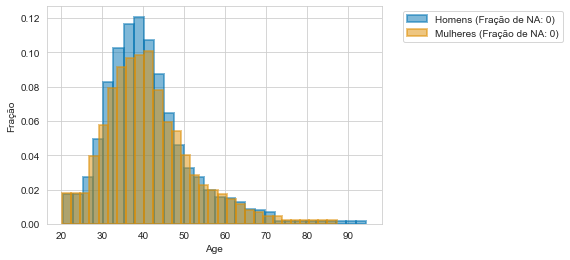

In [12]:
dict_dfs = {'Homens': df[df['Gender'] == 'Male'],
           'Mulheres': df[df['Gender'] == 'Female']}
analise_exp2 = dsa.AvaliaDatasetsDistribuicoes(dict_dfs, num_div = 20, num_cat = 10)
analise_exp2.trata_coluna(dict_dfs, 'Age')
analise_exp2.grafico_distribuicao('Age', bins = 30)

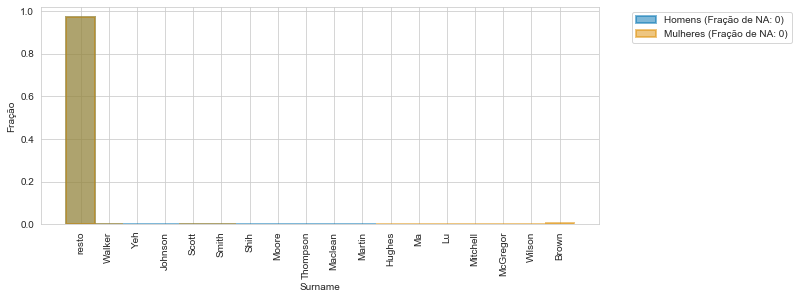

In [13]:
analise_exp2.trata_coluna(dict_dfs, 'Surname')
analise_exp2.grafico_distribuicao('Surname', figsize = [10, 4], rot = 90)

In [14]:
vars_cat = ['Geography', 'Gender']
vars_num = ['CreditScore',
            'Age',
            'Tenure',
            'Balance',
            'NumOfProducts',
            'HasCrCard',
            'IsActiveMember',
            'EstimatedSalary']

# Conjunto de Teste

In [15]:
frac_teste = 0.2

ss_teste = StratifiedShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df.values, df[nome_alvo].values))[0] 

df_intermed = df.iloc[split_teste[0]]
df_teste = df.iloc[split_teste[1]]

frac_teste = 0.15

df_aux = df[colunas_id].groupby('Surname').count().sort_values('CustomerId', ascending = True)
df_aux['Acum_Frac'] = df_aux['CustomerId'].cumsum()/df_aux['CustomerId'].sum()
surname_teste = list(df_aux[:(df_aux['Acum_Frac'] <= frac_teste).sum() + 1].index)

df_intermed = df.loc[~df['Surname'].isin(surname_teste)]
df_teste = df.loc[df['Surname'].isin(surname_teste)]

In [16]:
(df_teste[colunas_id].groupby('Surname').count() > 1).sum()/len(np.unique(df_teste['Surname']))

CustomerId    0.369947
dtype: float64

# Treino/Val "Ingênuo"

In [17]:
frac_val = 0.3
num_splits = 1

ss = StratifiedShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
#ss = StratifiedKFold(n_splits = num_splits, shuffle = True, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[nome_alvo].values))  

In [18]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = None, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [19]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo]),
               'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    #dict_Xy.update({'Treino_' + str(i+1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo])})
    #dict_Xy.update({'Treino_' + str(i+1): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    i = i + 1

dict_Xy = {}

df_aux = df_intermed_t[df_intermed_t[nome_alvo] == 0]
dict_Xy.update({'Treino_' + str(0): (df_aux.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_aux[nome_alvo])})

df_aux = df_intermed_t[df_intermed_t[nome_alvo] == 1]
dict_Xy.update({'Treino_' + str(1): (df_aux.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_aux[nome_alvo])})

t = time.time()

clf = lrn.SeriesMultiGradientClassifier()
clf.setup_datasets(dict_Xy, laurent = True, ordem = 2, apenas_interacoes = False)
clf.setup_optimizer(alpha = 0.01, epsilon = 1e-6, early_stop = 10, filtro_atualizacao_thetas = True)
clf.fit(num_passos = 1000, verbose = 1, plot = False)

print(time.time() - t)

clf.grafico_vies_variancia(ymin = 0)
clf.grafico_importancias()
clf.grafico_importancias_termos(num_vars = 20)

In [20]:
from catboost import CatBoostClassifier

clf = CatBoostClassifier(depth = 1, learning_rate = 0.05, iterations = 5000)

clf.fit(dict_Xy['Treino_1'][0], dict_Xy['Treino_1'][1], eval_set = [dict_Xy['Treino_1'], dict_Xy['Treino_2']],
        verbose = 0, plot = True)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

In [22]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
probs_intermed = clf.predict_proba(df_intermed_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]
probs_teste = clf.predict_proba(df_teste_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]

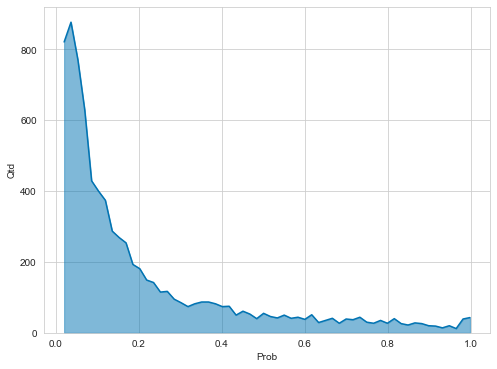

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

qtds, probs = np.histogram(probs_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(probs[1:], qtds, color = paleta_cores[0])
    axs.fill_between(probs[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Prob')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [24]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Prob'] = probs_intermed
df_teste_aval['Prob'] = probs_teste

In [26]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaoclf = aml.AvaliaDatasetsClassificacao(dict_dfs, 
                                               nome_alvo, 
                                               'Prob', 
                                               num_div_prob = 100, 
                                               num_div = 10, 
                                               num_cat = 5, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [27]:
avaliacaoclf.valor_metricas().loc[['LogLoss', 'CoefLogLoss', 'CoefLogLoss_ref',
                                  'AUC', 'KS', 'IG', 'IG_2D', 'Frac_Incerto_2D', 
                                  'Prob_Corte', 'Prob0_Corte', 'Prob1_Corte',
                                  'Acurácia_Balanceada', 'Acurácia_Balanceada_2D',
                                  'P(0|0)', 'P_2D(0|0)', 'Frac_0',
                                  'P(1|1)', 'P_2D(1|1)', 'Frac_1'], :]

Treino     Teste
LogLoss                 0.343259  0.345400
CoefLogLoss             0.321029  0.316333
CoefLogLoss_ref         0.321029  0.316333
AUC                     0.857740  0.854380
KS                      0.553275  0.538591
IG                      0.231556  0.227598
IG_2D                   0.283331  0.285761
Frac_Incerto_2D         0.277000  0.283500
Prob_Corte              0.286634  0.388265
Prob0_Corte             0.146793  0.080990
Prob1_Corte             0.491592  0.526738
Acurácia_Balanceada     0.773024  0.763298
Acurácia_Balanceada_2D  0.840301  0.841198
P(0|0)                  0.912261  0.909031
P_2D(0|0)               0.941868  0.940823
Frac_0                  0.796250  0.796500
P(1|1)                  0.578530  0.556936
P_2D(1|1)               0.750736  0.741573
Frac_1                  0.203750  0.203500

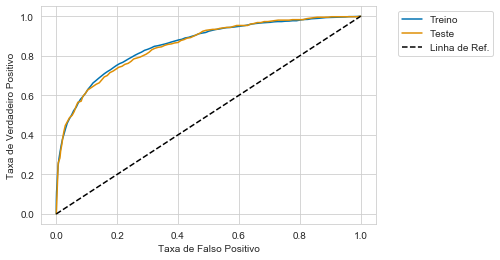

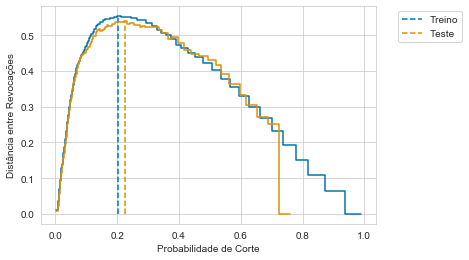

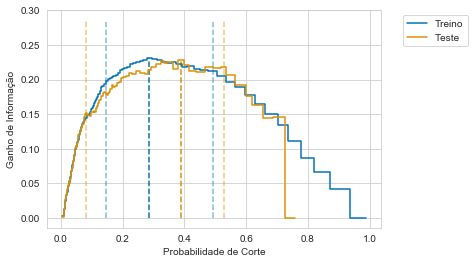

In [28]:
avaliacaoclf.grafico_roc()
avaliacaoclf.grafico_ks()
avaliacaoclf.grafico_informacao(mostrar_ig_2d = True)

avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Prob', num_div = 25, parametros_padrao = False)
avaliacaoclf.grafico_distribuicao('Prob')
avaliacaoclf.grafico_probabilidade_condicional('Prob', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('Prob', metricas = ['AUC', 'Acurácia_Balanceada'], rot = 90)

avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'NumOfProducts')
avaliacaoclf.grafico_distribuicao('NumOfProducts')
avaliacaoclf.grafico_probabilidade_condicional('NumOfProducts')
avaliacaoclf.grafico_metricas_condicionais('NumOfProducts', metricas = ['AUC', 'Acurácia_Balanceada'])

avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Age')
avaliacaoclf.grafico_distribuicao('Age')
avaliacaoclf.grafico_probabilidade_condicional('Age', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('Age', metricas = ['AUC', 'Acurácia_Balanceada'], rot = 90)

# Split por Sobrenome

In [29]:
df_aux = df_intermed[colunas_id].groupby('Surname').count().sort_values('CustomerId', ascending = False)
df_aux['Acum_Frac'] = df_aux['CustomerId'].cumsum()/df_aux['CustomerId'].sum()
surname_val = list(df_aux[:(df_aux['Acum_Frac'] <= 0.3).sum() + 1].index)

In [30]:
dict_Xy = {}

df_treino_t = df_intermed_t.loc[~df_intermed_t['Surname'].isin(surname_val)]
df_val_t = df_intermed_t.loc[df_intermed_t['Surname'].isin(surname_val)]

dict_Xy.update({'Treino': (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo]),
               'Val': (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})

In [31]:
(df_val_t[colunas_id].groupby('Surname').count() > 1).sum()/len(np.unique(df_val_t['Surname']))

CustomerId    1.0
dtype: float64

t = time.time()

clf = lrn.SeriesMultiGradientClassifier()
clf.setup_datasets(dict_Xy, laurent = True, ordem = 2, apenas_interacoes = False)
clf.setup_optimizer(alpha = 0.01, epsilon = 1e-6, early_stop = 10, filtro_atualizacao_thetas = True)
clf.fit(num_passos = 1000, verbose = 1, plot = False)

print(time.time() - t)

clf.grafico_vies_variancia(ymin = 0)
clf.grafico_importancias()
clf.grafico_importancias_termos(num_vars = 20)

In [32]:
from catboost import CatBoostClassifier

clf = CatBoostClassifier(depth = 1, learning_rate = 0.05, iterations = 5000)

clf.fit(dict_Xy['Treino'][0], dict_Xy['Treino'][1], eval_set = [dict_Xy['Treino'], dict_Xy['Val']],
        verbose = 0, plot = True)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

In [33]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
probs_intermed = clf.predict_proba(df_intermed_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]
probs_teste = clf.predict_proba(df_teste_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]

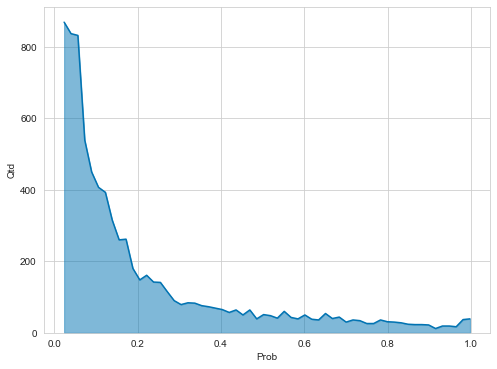

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

qtds, probs = np.histogram(probs_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(probs[1:], qtds, color = paleta_cores[0])
    axs.fill_between(probs[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Prob')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [35]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Prob'] = probs_intermed
df_teste_aval['Prob'] = probs_teste

In [37]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaoclf = aml.AvaliaDatasetsClassificacao(dict_dfs, 
                                               nome_alvo, 
                                               'Prob', 
                                               num_div_prob = 100, 
                                               num_div = 10, 
                                               num_cat = 5, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [38]:
avaliacaoclf.valor_metricas().loc[['LogLoss', 'CoefLogLoss', 'CoefLogLoss_ref',
                                  'AUC', 'KS', 'IG', 'IG_2D', 'Frac_Incerto_2D', 
                                  'Prob_Corte', 'Prob0_Corte', 'Prob1_Corte',
                                  'Acurácia_Balanceada', 'Acurácia_Balanceada_2D',
                                  'P(0|0)', 'P_2D(0|0)', 'Frac_0',
                                  'P(1|1)', 'P_2D(1|1)', 'Frac_1'], :]

Treino     Teste
LogLoss                 0.345179  0.341635
CoefLogLoss             0.317230  0.323784
CoefLogLoss_ref         0.317230  0.323784
AUC                     0.855688  0.858751
KS                      0.555065  0.551700
IG                      0.227958  0.234202
IG_2D                   0.279017  0.297484
Frac_Incerto_2D         0.192250  0.189500
Prob_Corte              0.241465  0.363553
Prob0_Corte             0.223869  0.140830
Prob1_Corte             0.575951  0.521342
Acurácia_Balanceada     0.777613  0.772515
Acurácia_Balanceada_2D  0.784304  0.783350
P(0|0)                  0.920089  0.918100
P_2D(0|0)               0.922738  0.921996
Frac_0                  0.796250  0.796500
P(1|1)                  0.534159  0.526508
P_2D(1|1)               0.814628  0.818182
Frac_1                  0.203750  0.203500

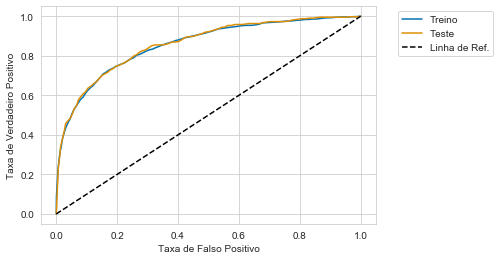

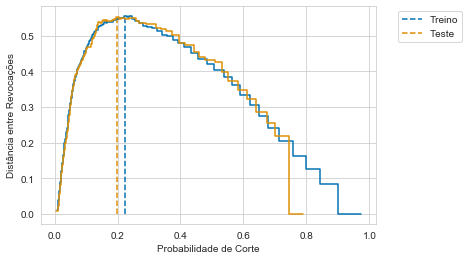

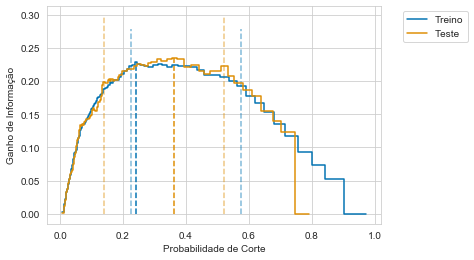

In [39]:
avaliacaoclf.grafico_roc()
avaliacaoclf.grafico_ks()
avaliacaoclf.grafico_informacao(mostrar_ig_2d = True)

In [40]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'CreditScore')
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Gender')

In [41]:
aa = avaliacaoclf.avaliadores_individuais()['Treino']

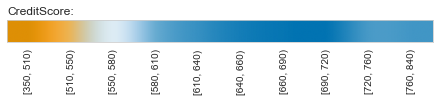

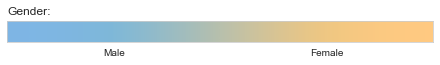

In [42]:
aa.barra_calor('CreditScore', rot = 90)
aa.barra_calor('Gender', alpha_max = 0.5)

In [46]:
cols_features = ['CreditScore', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Geography_France', 'Geography_Germany', 'Geography_Spain',
       'Gender_Female', 'Gender_Male']

df_intermed_t2 = df_intermed_t.copy()
df_intermed_t2['Prob'] = clf.predict_proba(df_intermed_t[cols_features])[:,1]

df_teste_t2 = df_teste_t.copy()
df_teste_t2['Prob'] = clf.predict_proba(df_teste_t[cols_features])[:,1]

In [47]:
aa = exp.CamClassificacao(clf, df_intermed_t2, df_teste_t2.iloc[15:30], cols_features = cols_features, num_loop = 25, 
                          random_state = 42)

In [48]:
for i in range(15, 30):
    display(aa.styler_mapa_calor(df_teste_t2.iloc[[i]], 
                                 ordenar_linhas = 'descending', ordenar_colunas = 'descending', 
                                 opacity_text = True))

In [73]:
importlib.reload(exp)

<module 'AleExplainers' from '<PASTA_DAS_BIBLIOTECAS>\\AleExplainers.py'>